# Finite Element Speckle Dic

## 1. Problem

Recover the two-component apparent solid-surface displacement at all 15 shared finite-element nodes from two repository-supplied speckle frames. Intensity transport is nonlinear, texture constrains motion anisotropically, and fractional-pixel interpolation affects the estimate. Frame timing and physical pixel pitch are unavailable.

Save `output/reconstruction.npz` with key `reconstruction`, finite real float32 or float64 (1,15,2), in pixels, axes batch/node/component (x right,y up). Values are increments from the supplied reference nodes. There is no translation, rotation, sign or scale alignment. The selected small two-frame Q4 reconstruction does not reproduce the paper's full tensile sequence or Hencky-strain figure. Derived Green-Lagrange strain is a diagnostic, not a separate measured inverse target.

## 2. Data

The observations are the repository-supplied `Examples/example_data/ut_151.tif` and `ut_156.tif` from [muDIC](https://github.com/PolymerGuy/muDIC), immutable commit `c2c54018ed8c9aba2eaf3a82bc79c2cb56878d01`. Each original is `(2050,871)` uint8. The upstream row reversal and selected fixed crop are reproduced exactly as `array[::-1][350:770,290:550].astype(float64)`, yielding `(420,260)` images with unchanged digital counts. No resampling, smoothing or synthetic deformation was introduced. The mesh is a prescribed geometry independent of the inferred displacement. The files lack sufficient acquisition metadata to establish specimen material, physical length or frame interval; this notebook therefore reports apparent displacement in pixels and does not assert calibrated strain accuracy.

All visible arrays are in `data/raw_data.npz`.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| reference_image | (1, 420, 260) | float64 | Reference grayscale intensity, original 8-bit digital counts represented exactly as float64; axes batch, y, x. |
| deformed_image | (1, 420, 260) | float64 | Deformed grayscale intensity in digital counts, with the same orientation and crop. |
| nodes | (1, 15, 2) | float64 | Reference node positions in pixels; last axis x right, y up. |
| elements | (1, 8, 4) | int64 | Dimensionless zero-based node indices, ordered lower-left, lower-right, upper-right, upper-left. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Image dimensions | 420 by 260 | pixel | Height by width of the bound crop. |
| Pixel pitch | 1 | pixel | Coordinate spacing; conversion to metres is unavailable. |
| Origin | (0, 0) | pixel | Centre of the lower-left stored pixel. |
| Axis convention | x right; y up | dimensionless | Stored row index increases upward. |
| Reference mesh bounds | x=50 to 210; y=50 to 370 | pixel | Common field of interest in both images. |
| Mesh topology | 2 columns by 4 rows | element | Structured Q4 mesh, 80 by 80 pixels per element. |
| Optical geometry | single-camera 2D projection | dimensionless | Only apparent in-plane displacements are observable. |
| Illumination convention | approximate brightness conservation | digital count | No brightness normalization is prescribed. |
| Boundary conditions | all mesh nodes free | dimensionless | No imposed zero displacement or known target motion. |
| Noise calibration | unavailable | digital count | No calibrated statistical noise model is supplied. |
| Exposure and frame interval | unavailable | second | Output is displacement, not velocity. |

The following cell actively loads the visible arrays. Hidden standard-method results are loaded only later for identified scientific comparisons; no target-derived calibration is supplied.

In [1]:
from pathlib import Path
import sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root/'src').exists():
    root = root.parent
assert (root/'data/raw_data.npz').exists()
sys.path.insert(0, str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import green_strain, prepare_reference, filtered_frames, sample_element
from src.visualization import plot_comparison
reference, deformed, nodes, elements = load_data(root/'data/raw_data.npz')
print('Observed arrays:', reference.shape, deformed.shape, 'mesh:', nodes.shape, elements.shape)
with np.load(root/'data/raw_data.npz',allow_pickle=False) as visible:
    for key in visible.files:
        print(key,visible[key].shape,visible[key].dtype)

Observed arrays: (420, 260) (420, 260) mesh: (15, 2) (8, 4)
reference_image (1, 420, 260) float64
deformed_image (1, 420, 260) float64
nodes (1, 15, 2) float64
elements (1, 8, 4) int64


## 3. Physics

Brightness conservation relates reference coordinate X and current coordinate x through $I_1(x)=I_0(X)+\epsilon$. Intensities I0/I1 are unchanged digital counts and epsilon is photometric/model mismatch. Within each Q4 element,

$$X=N X_n,\qquad x=N x_n,\qquad u=N(x_n-X_n),$$

where Xn,xn are four-by-two nodal coordinates in pixels and $N=[(1-\xi)(1-\eta),\xi(1-\eta),\xi\eta,(1-\xi)\eta]$ for parent coordinates xi,eta in[0,1]. Nodes are ordered lower-left,lower-right,upper-right,upper-left; adjacent elements share nodes and hence displacement continuity. The bound mesh is an axis-aligned2-by4 grid,15 nodes,80-pixel elements. Array row increases upward after the upstream row reversal; origin is the lower-left pixel center. No fixed node or imposed material motion is assumed.

For physical interpretation only, D is the shape derivative matrix at the element center, $F=(x_n^TD)(X_n^TD)^{-1}$ and $E=(F^TF-I)/2$. F and Green-Lagrange E are dimensionless; rigid rotations give E=0. This independently derived convention avoids the paper's ambiguous printed reference-Jacobian entries and is not claimed to reproduce upstream tensor-storage choices.

## 4. Method

The objective is $R=\sum_{e,p}[I_0(X_p)-I_1(N_p x_n)]^2$, with unit weight for each integer pixel in each element's inclusive rectangle. Shared edge pixels deliberately contribute once per incident element. Each local matrix $B_e$ is the transpose of the reference image-gradient Jacobian, using central-difference gradients times shape functions. The gather/scatter assembly below builds the shared nodal system. Each modified Newton increment solves that system, followed by addition to the current nodes. The reference gradients and H stay fixed. Intensities are evaluated using the upstream order-four spline interpolation with prefiltering, matching its image-crop convention. The stop criterion is an increment smaller than $10^{-8}$ pixels, at most 80 updates. No regularizer or brightness normalization is used.

The initial current nodes equal the supplied reference nodes. The central-difference gradient uses one-pixel spacing and includes no image-count normalization. Every integer pixel on both element edges is counted for each incident element. Full-image order-four spline prefilter uses mirror boundary; subsequent fixed100-square padded element crops use interpolation with prefilter=False and constant-zero exterior. Pad10, unit update steps, max80 and tolerance1e-8px are the actual defaults. The bound queries stay within those crops; nonconvergence raises RuntimeError and no hidden regularization is inserted.

For element e, define the gather matrix $T_e$ that selects its four x increments followed by its four y increments from the globally interleaved 30-component vector q. Its transpose scatters and sums shared-node contributions. With the local reference-gradient transpose $B_e$ of shape `(8,6561)`, the pixel Jacobian is $J_e=B_e^T T_e$. Thus the assembled system uses

```math
H=\sum_e T_e^T B_e B_e^T T_e,\qquad
C=\sum_e T_e^T B_e r_e,\qquad \delta=H^{-1}C.
```

The factor two from differentiating the sum of squared residuals cancels on both sides. No pixel-count normalization is applied. After adding the increment to current nodes, the precise stopping test is `max(abs(delta)) < 1e-8` pixels; at most 80 updates are permitted and exhaustion raises an error.


## 5. Results

All fresh results below are actively reconstructed with the shipped local modules. Archived upstream arrays remain explicitly identified comparison measurements, never measured truth or a replacement for computation.

In [2]:
started = time.perf_counter()
displacement, history = reconstruct(reference, deformed, nodes, elements)
runtime = time.perf_counter()-started
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz', reconstruction=displacement[None])
np.savez_compressed(root/'notebooks/reference_outputs/cleaned_measurements.npz', reconstruction=displacement[None], history=history)
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz', allow_pickle=False) as f:
    upstream = f['reconstruction'][0]
print('Fresh local runtime (seconds):', runtime)
print('Updates:', len(history), 'final maximum increment:', history[-1,1])
print('Maximum absolute displacement difference vs reproduced upstream:', np.max(np.abs(displacement-upstream)))

Fresh local runtime (seconds): 0.03773770004045218
Updates: 10 final maximum increment: 4.309769881326303e-09
Maximum absolute displacement difference vs reproduced upstream: 0.0


### Independent reproduced reference and fresh measurement
The upstream run used the unchanged muDIC Q4 reference and correlation functions on these exact packaged images. Its output is a standard-method baseline, never physical truth. NCC below means uncentered cosine similarity; NRMSE is RMS component error divided by the dynamic range of the upstream displacement. The pass criterion is pixel displacement RMSE with no pose or scale alignment. Numerical agreement demonstrates extraction fidelity; it does not measure experimental accuracy.

In [3]:
command = [sys.executable, str(root/'evaluation/judge.py'), '--prediction', str(root/'output/reconstruction.npz'), '--report', str(root/'output/judge_report.json')]
subprocess.run(command, cwd=root, check=True, capture_output=True)
report = json.loads((root/'output/judge_report.json').read_text())
assert report['passed']
rmse = float(np.sqrt(np.mean((displacement-upstream)**2)))
ncc = float(np.sum(displacement*upstream)/(np.linalg.norm(displacement)*np.linalg.norm(upstream)))
nrmse = rmse/float(np.ptp(upstream))
assert np.isclose(report['metrics']['displacement_rmse_pixels'],rmse)
assert np.isclose(report['metrics']['ncc'],ncc)
assert np.isclose(report['metrics']['nrmse'],nrmse)
print('Measurement                 pixel RMSE         NCC       dynamic-range NRMSE')
print(f'Reproduced upstream         {0.:.12g}                {1.:.9g}          {0.:.12g}')
print(f'Fresh cleaned code          {rmse:.12g}                {ncc:.9g}          {nrmse:.12g}')
print('Judge:', report['status'], report['thresholds'])

Measurement                 pixel RMSE         NCC       dynamic-range NRMSE


Reproduced upstream         0                1          0
Fresh cleaned code          0                1          0
Judge: pass {'displacement_rmse_pixels': {'comparison': '<=', 'boundary': 1e-05}}


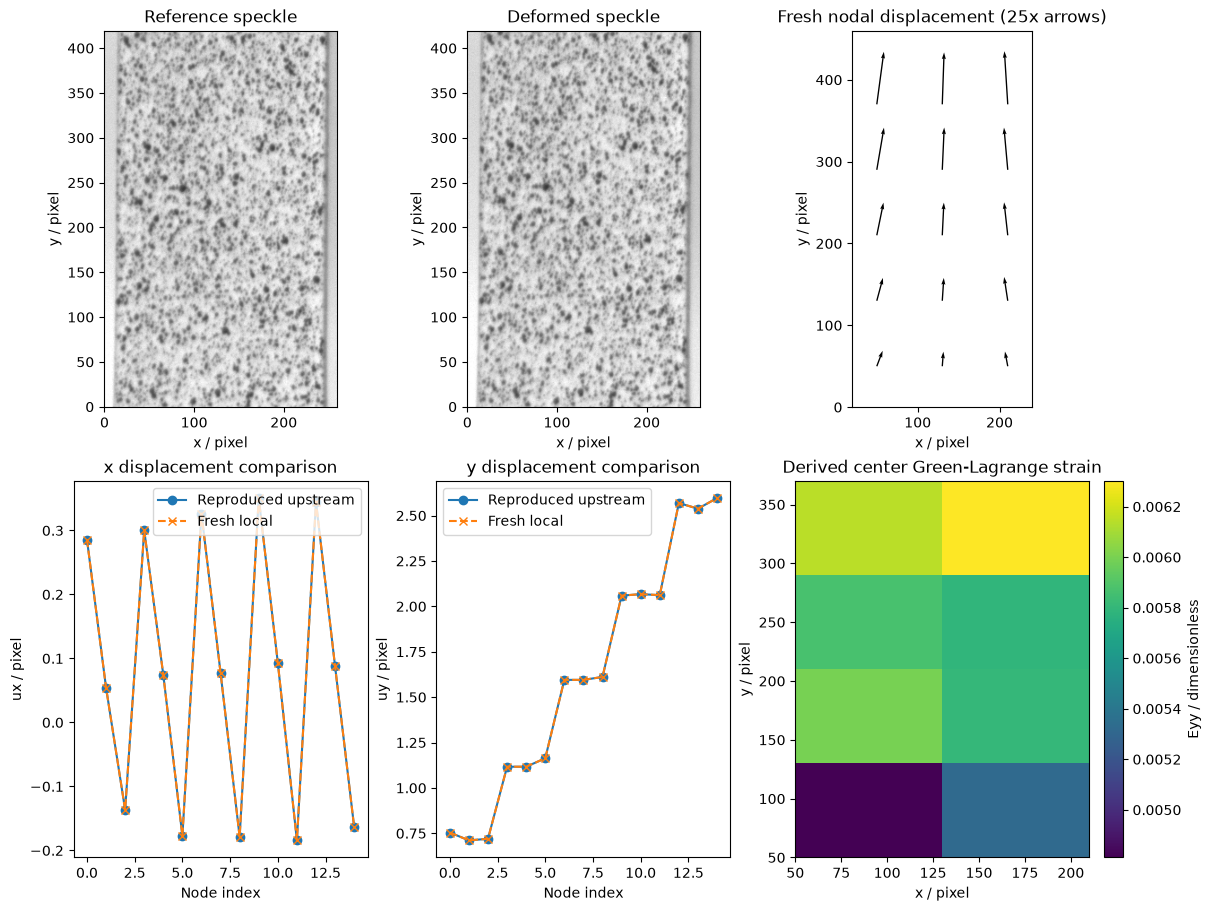

In [4]:
fig = plot_comparison(reference,deformed,nodes,elements,displacement,upstream)
plt.show()

### Physical consistency and convergence
The figure pairs each displacement component from the original method and the fresh computation. Arrows are enlarged 25 times for visibility. The strain panel is derived from the fresh nodal deformation, not an additional measured truth. At each element center, define $F=(x_n^T D)(X_n^T D)^{-1}$, where D contains parent-coordinate shape gradients. The Green-Lagrange strain is $E=(F^T F-I)/2$; it is dimensionless and vanishes under rigid rotations. Analytic tests check this property independently of upstream code. The following computes the final brightness residual rather than assuming numerical parity establishes physical fidelity.

Initial/final photometric RMSE (digital counts): 18.65430566789413 5.3060448354762935
Derived Eyy range: 0.004811322938404361 0.0063014209146108335


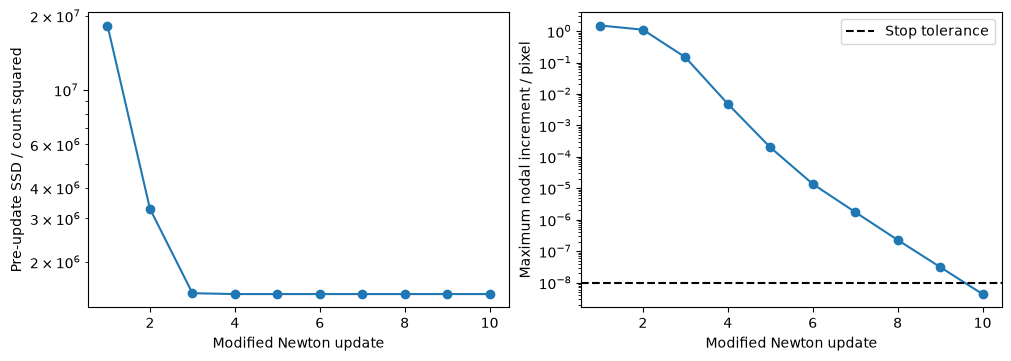

{
  "runtime_seconds": 0.03773770004045218,
  "iterations": 10,
  "initial_photometric_rmse": 18.65430566789413,
  "final_photometric_rmse": 5.3060448354762935
}


In [5]:
blocks,_ = prepare_reference(reference,nodes,elements)
frames=filtered_frames(deformed,nodes,elements)
def image_rmse(current):
    residuals=[]
    for e,(N,B,I0),(frame,lo) in zip(elements,blocks,frames):
        residuals.append(I0-sample_element(frame,lo,N,current[e]))
    return float(np.sqrt(np.mean(np.concatenate(residuals)**2)))
initial_rmse=image_rmse(nodes)
final_rmse=image_rmse(nodes+displacement)
print('Initial/final photometric RMSE (digital counts):',initial_rmse,final_rmse)
assert final_rmse<initial_rmse
strain=green_strain(nodes,nodes+displacement,elements)
print('Derived Eyy range:',strain[:,1,1].min(),strain[:,1,1].max())
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
axes[0].semilogy(np.arange(1,len(history)+1),history[:,0], 'o-')
axes[0].set(xlabel='Modified Newton update',ylabel='Pre-update SSD / count squared')
axes[1].semilogy(np.arange(1,len(history)+1),history[:,1], 'o-')
axes[1].axhline(1e-8,color='k',linestyle='--',label='Stop tolerance')
axes[1].set(xlabel='Modified Newton update',ylabel='Maximum nodal increment / pixel')
axes[1].legend()
plt.show()
print(json.dumps(dict(runtime_seconds=runtime,iterations=len(history),initial_photometric_rmse=initial_rmse,final_photometric_rmse=final_rmse),indent=2))

## 6. Conclusion

The fresh computation reconstructs the full selected Q4 field, agrees with independently captured original-code stages and final displacement, and reduces the intensity mismatch. Residual mismatch remains from image noise, interpolation and departure from brightness conservation. This task is the small two-frame benchmark, not reproduction of the paper's entire tensile sequence or its Hencky-strain figure. The paper explicitly supports Q4 as the linear finite-element subset of the framework. The repository's example images are retained as supplied; specimen identity and timing for these exact files are not independently asserted.

Reference: S. N. Olufsen, M. E. Andersen and E. Fagerholt, *muDIC: An open-source toolkit for digital image correlation*, SoftwareX 11 (2020), 100391, DOI 10.1016/j.softx.2019.100391. The published version, exact code revision, download evidence, hashes, tolerances and validation are indexed in `test/validation.md`.